In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [4]:
df = pd.read_csv("sales_data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
df.head()

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,Sales,Quantity,Discount,Cost,Profit
0,ORD-100001,2022-01-01,CUST-0356,Joseph Brown,Charging Cable,Accessories,South,80.66,7,0.00,26.70,53.96
1,ORD-100002,2022-01-01,CUST-0127,John Patel,Sticky Notes,Office Supplies,West,16.71,3,0.05,7.97,8.74
2,ORD-100003,2022-01-01,CUST-0411,Patricia Lewis,Mechanical Keyboard,Accessories,East,262.76,3,0.00,143.88,118.88
3,ORD-100004,2022-01-02,CUST-0387,Mateo Johnson,Executive Desk,Furniture,Central,1467.05,2,0.05,971.34,495.71
4,ORD-100005,2022-01-02,CUST-0432,Thomas Taylor,Laptop Bag,Accessories,East,67.81,1,0.00,33.83,33.98


In [6]:
df.shape # Dataset Size

(10000, 12)

In [7]:
df.columns # Column names

Index(['Order ID', 'Order Date', 'Customer ID', 'Customer Name', 'Product',
       'Category', 'Region', 'Sales', 'Quantity', 'Discount', 'Cost',
       'Profit'],
      dtype='object')

In [8]:
df.info # Data Types

<bound method DataFrame.info of         Order ID  Order Date Customer ID   Customer Name              Product  \
0     ORD-100001  2022-01-01   CUST-0356    Joseph Brown       Charging Cable   
1     ORD-100002  2022-01-01   CUST-0127      John Patel         Sticky Notes   
2     ORD-100003  2022-01-01   CUST-0411  Patricia Lewis  Mechanical Keyboard   
3     ORD-100004  2022-01-02   CUST-0387   Mateo Johnson       Executive Desk   
4     ORD-100005  2022-01-02   CUST-0432   Thomas Taylor           Laptop Bag   
...          ...         ...         ...             ...                  ...   
9995  ORD-109996  2024-12-31   CUST-0356    Joseph Brown      4K Monitor 27in   
9996  ORD-109997  2024-12-31   CUST-0422   Richard Rossi     Cloud Backup 1TB   
9997  ORD-109998  2024-12-31   CUST-0409       Li Taylor         Sticky Notes   
9998  ORD-109999  2024-12-31   CUST-0278    Mateo Wilson            USB-C Hub   
9999  ORD-110000  2024-12-31   CUST-0478   Richard Perez          Label Maker

In [9]:
df.isnull().sum() # missing values

Order ID         0
Order Date       0
Customer ID      0
Customer Name    0
Product          0
Category         0
Region           0
Sales            0
Quantity         0
Discount         0
Cost             0
Profit           0
dtype: int64

In [10]:
df.duplicated().sum() # Duplicate rows

np.int64(0)

In [11]:
df["Order ID"].duplicated().sum() # Order ID duplicates

np.int64(0)

In [12]:
df["Order Date"] = pd.to_datetime(df["Order Date"]) # coverting Date in proper Formate

In [13]:
df["Order Date"].dtype

dtype('<M8[ns]')

In [14]:
print("Stare Date:", df["Order Date"].min())
print("End Date:", df["Order Date"].max()) # Date range 

Stare Date: 2022-01-01 00:00:00
End Date: 2024-12-31 00:00:00


In [15]:
df[["Sales", "Quantity", "Discount", "Cost", "Profit"]].describe() # Numerical Dataset

,Sales,Quantity,Discount,Cost,Profit
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,446.617494,3.076500,0.123605,374.988105,71.629389
std,591.302978,1.966173,0.107973,588.857087,184.930576
min,4.530000,1.000000,0.000000,2.530000,-1408.560000
25%,74.210000,2.000000,0.050000,37.820000,15.910000
50%,222.790000,3.000000,0.100000,145.325000,43.875000
75%,559.247500,4.000000,0.200000,426.762500,106.930000
max,7403.360000,14.000000,0.400000,6795.420000,3365.760000


In [16]:
Profit_check = (df["Sales"] - df["Cost"]) - df["Profit"]
Profit_check.abs().max() # Profit Formula verification (Profit = Sales - Cost)


6.821210263296962e-13

In [17]:
loss_transactions = df[df["Profit"] < 0]

print("Loss-making transactions:", len(loss_transactions)) # Negative Profit Check

Loss-making transactions: 1289


In [18]:
loss_transactions.head(10) #Loss-Making Transactions 

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,Sales,Quantity,Discount,Cost,Profit
7,ORD-100008,2022-01-03,CUST-0581,Sarah Silva,Conference Table,Furniture,East,1274.36,1,0.00,1285.39,-11.03
12,ORD-100013,2022-01-03,CUST-0410,Li Silva,Water Dispenser,Appliances,North,534.14,2,0.10,549.51,-15.37
17,ORD-100018,2022-01-04,CUST-0002,Sneha White,Tablet 10in,Electronics,East,375.25,1,0.20,411.41,-36.16
21,ORD-100022,2022-01-05,CUST-0551,Matthew Garcia,Gaming Laptop X,Electronics,East,1524.74,1,0.15,1664.19,-139.45
24,ORD-100025,2022-01-05,CUST-0178,David Tanaka,Gaming Laptop X,Electronics,West,1649.92,1,0.15,1678.69,-28.77
42,ORD-100043,2022-01-07,CUST-0522,Thomas Davis,Gaming Laptop X,Electronics,North,1254.84,1,0.30,1732.43,-477.59
45,ORD-100046,2022-01-07,CUST-0532,Isabella Khan,Smartphone Z,Electronics,Central,1425.58,2,0.15,1588.89,-163.31
61,ORD-100062,2022-01-10,CUST-0067,Jennifer Martin,Microwave Oven,Appliances,West,210.84,2,0.25,238.99,-28.15
66,ORD-100067,2022-01-10,CUST-0136,Daniel Rodriguez,Printer Toner,Office Supplies,East,125.31,2,0.30,130.27,-4.96
67,ORD-100068,2022-01-10,CUST-0014,Isabella Sharma,Mini Refrigerator,Appliances,East,285.63,1,0.15,291.31,-5.68


Buissness Analysis

In [19]:
total_revenue = df["Sales"].sum()

print("Total Revenue:", total_revenue) # Revenue Analysis

Total Revenue: 4466174.9399999995


In [20]:
total_profit = df["Profit"].sum()

print("Total Profit", total_profit) # Total Profit

Total Profit 716293.89


In [21]:
profit_margin = (total_profit / total_revenue) * 100

print("Overall Profit Margin:", round(profit_margin, 2), "%") # Profit Margin (Profit Margin = Total Profit / Total revenue * 100

Overall Profit Margin: 16.04 %


In [22]:
total_orders = df["Order ID"].nunique()
print("Total Orders:", total_orders) # Total Orders

Total Orders: 10000


In [23]:
total_customers = df["Customer ID"].nunique()

print("Total Customers:", total_customers) # Total Customers

Total Customers: 576


In [24]:
df["Month"] = df["Order Date"].dt.to_period("M")

monthly_revenue = df.groupby("Month")["Sales"].sum()

monthly_revenue # Revenue by Month 

Month
2022-01     93138.98
2022-02     81055.03
2022-03    101993.19
2022-04     88906.92
2022-05     83983.13
2022-06    106285.76
2022-07     95483.94
2022-08    124592.61
2022-09     89120.38
2022-10    135485.42
2022-11    168354.51
2022-12    163178.73
2023-01     74697.43
2023-02     98093.78
2023-03    104058.90
2023-04     94480.21
2023-05    125481.25
2023-06    121209.34
2023-07    105891.07
2023-08     94399.69
2023-09    116437.11
2023-10    121146.52
2023-11    199113.88
2023-12    222415.87
2024-01    109509.83
2024-02    104458.93
2024-03    126875.74
2024-04    132914.62
2024-05    117670.67
2024-06    130862.62
2024-07    126804.90
2024-08    135059.71
2024-09    134219.99
2024-10    163114.75
2024-11    180554.33
2024-12    195125.20
Freq: M, Name: Sales, dtype: float64

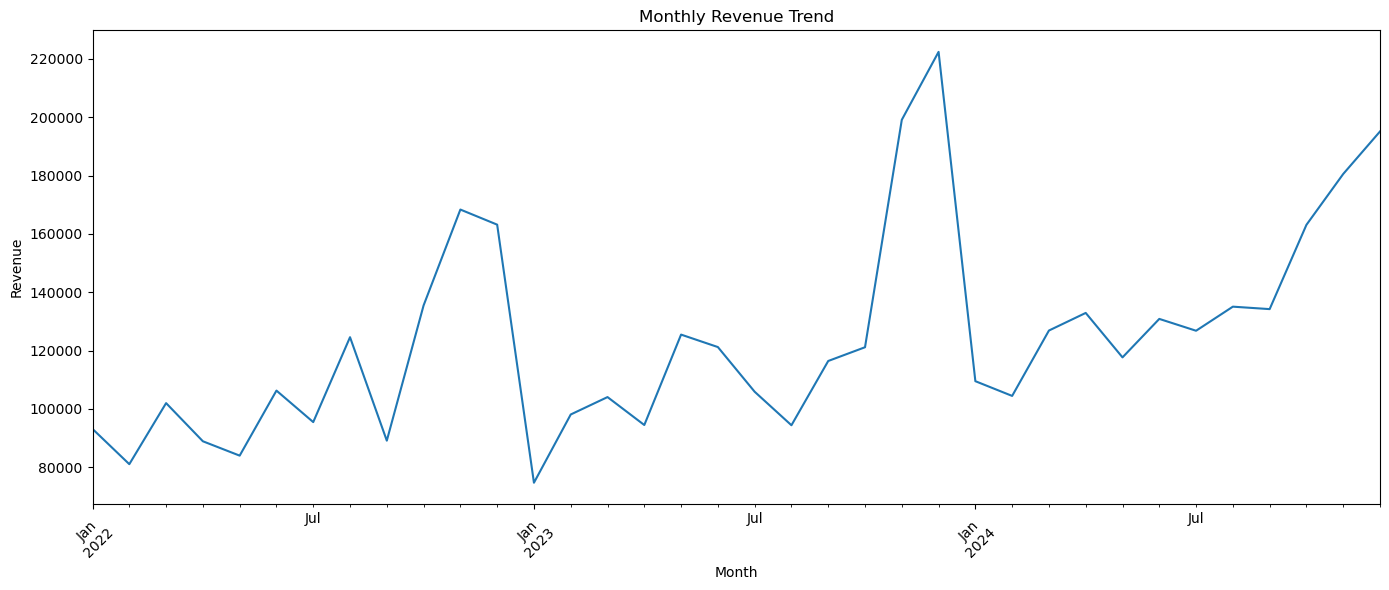

In [25]:
plt.figure(figsize=(14, 6))

monthly_revenue.plot()

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show() # Revenue Trend Graph

In [26]:
highest_month = monthly_revenue.idxmax()
highest_value = monthly_revenue.max()

print("Highest Revenue Month:", highest_month)
print("Revenue:", round(highest_value, 2)) #Highest revenue month

Highest Revenue Month: 2023-12
Revenue: 222415.87


In [27]:
lowest_month = monthly_revenue.idxmin()
lowest_value = monthly_revenue.min()

print("Lowest Revenue <onth:", lowest_month)
print("Revenue:", round(lowest_value, 2)) # Lowest revnue month

Lowest Revenue <onth: 2023-01
Revenue: 74697.43


In [28]:
yearly_revenue = df.groupby(df["Order Date"].dt.year)["Sales"].sum()

print(yearly_revenue) # is revenue growing along with time

Order Date
2022    1331578.60
2023    1477425.05
2024    1657171.29
Name: Sales, dtype: float64


In [29]:
yearly_growth = yearly_revenue.pct_change() * 100

print(yearly_growth.round(2)) # How it much Grows

Order Date
2022      NaN
2023    10.95
2024    12.17
Name: Sales, dtype: float64


In [30]:
df["Quarter"] = df["Order Date"].dt.to_period("Q")

quarterly_revenue = df.groupby("Quarter")["Sales"].sum()

quarterly_revenue # Quarterly Revenue

Quarter
2022Q1    276187.20
2022Q2    279175.81
2022Q3    309196.93
2022Q4    467018.66
2023Q1    276850.11
2023Q2    341170.80
2023Q3    316727.87
2023Q4    542676.27
2024Q1    340844.50
2024Q2    381447.91
2024Q3    396084.60
2024Q4    538794.28
Freq: Q-DEC, Name: Sales, dtype: float64

In [31]:
region_revenue = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

region_revenue # Revenue by Region

Region
East       1376225.04
North      1024203.41
West        860382.96
South       638679.54
Central     566683.99
Name: Sales, dtype: float64

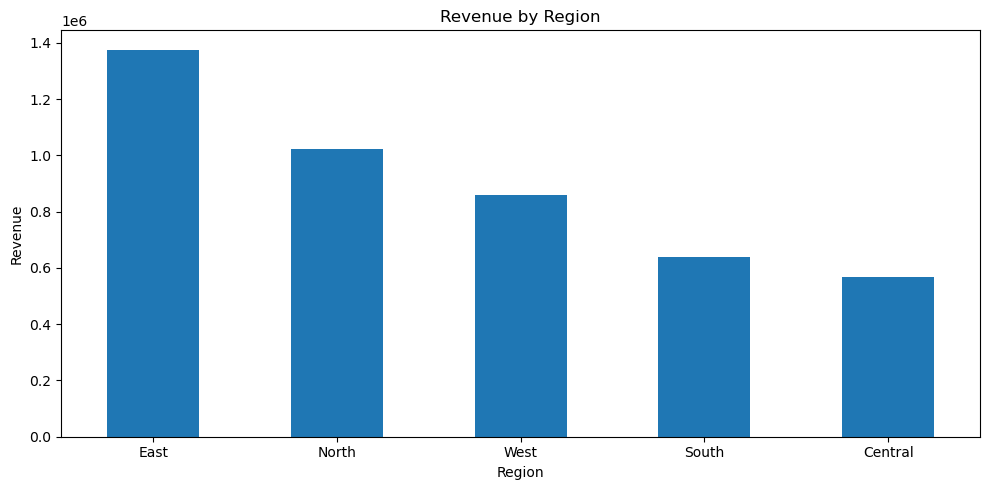

In [32]:
plt.figure(figsize=(10, 5))

region_revenue.plot(kind="bar")

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show() # Region chart

In [33]:
region_performance = df.groupby("Region").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum")
)

region_performance["Profit Margin %"] = (
    region_performance["Profit"] /
    region_performance["Revenue"] * 100
)

region_performance = region_performance.sort_values(
    "Revenue",
    ascending=False
)

region_performance.round(2) # Revenue Vs Profit By Region

,Revenue,Profit,Profit Margin %
Region,,,
East,1376225.04,226548.21,16.46
North,1024203.41,166299.63,16.24
West,860382.96,136038.16,15.81
South,638679.54,93172.80,14.59
Central,566683.99,94235.09,16.63


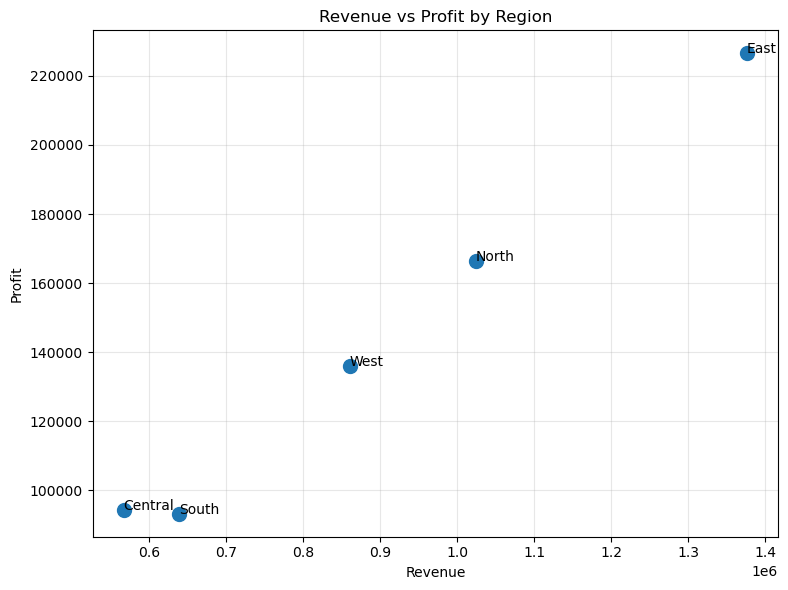

In [34]:
plt.figure(figsize=(8, 6))

plt.scatter(
    region_performance["Revenue"],
    region_performance["Profit"],
    s=100

)

for region in region_performance.index:
    plt.annotate(
        region,
        (
            region_performance.loc[region, "Revenue"],
            region_performance.loc[region, "Profit"]
        )
    )

plt.title("Revenue vs Profit by Region")
plt.xlabel("Revenue")
plt.ylabel("Profit")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show() # High Revenue ≠ High Profit

Product Analysis

In [35]:
product_revenue = (
    df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

product_revenue.head(10) # Product Performance

Product
Gaming Laptop X     538332.42
Smartphone Z        363418.37
Laptop Pro 15       303262.02
Laptop Air 13       302356.62
Conference Table    202434.67
Sofa 3-Seater       191292.01
Tablet 10in         163904.68
4K Monitor 27in     149927.58
Executive Desk      148048.51
Standing Desk       145895.03
Name: Sales, dtype: float64

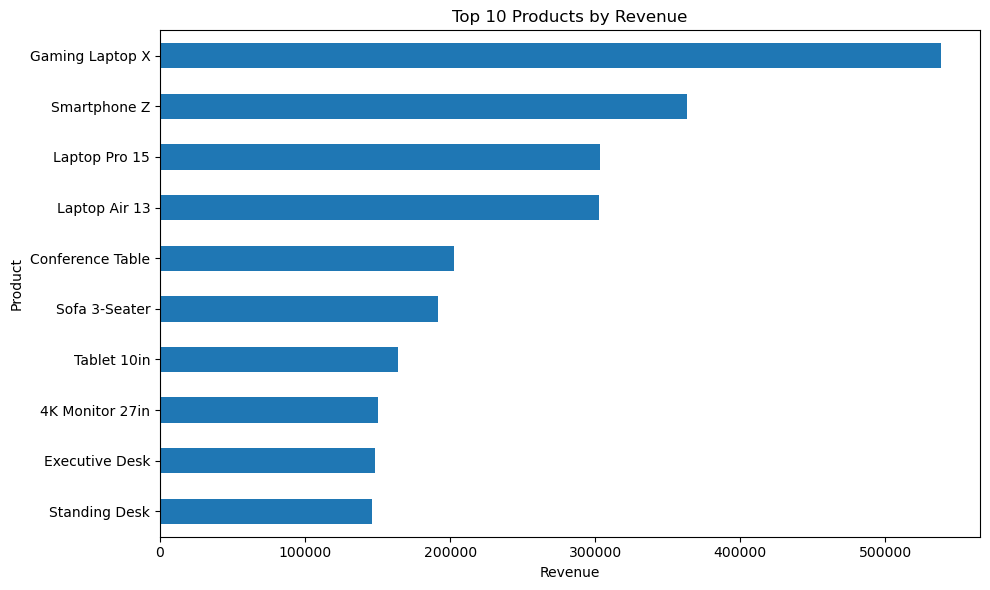

In [36]:
top_10_products = product_revenue.head(10)

plt.figure(figsize=(10, 6))

top_10_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.tight_layout()
plt.show() # Top 10 Products Chart

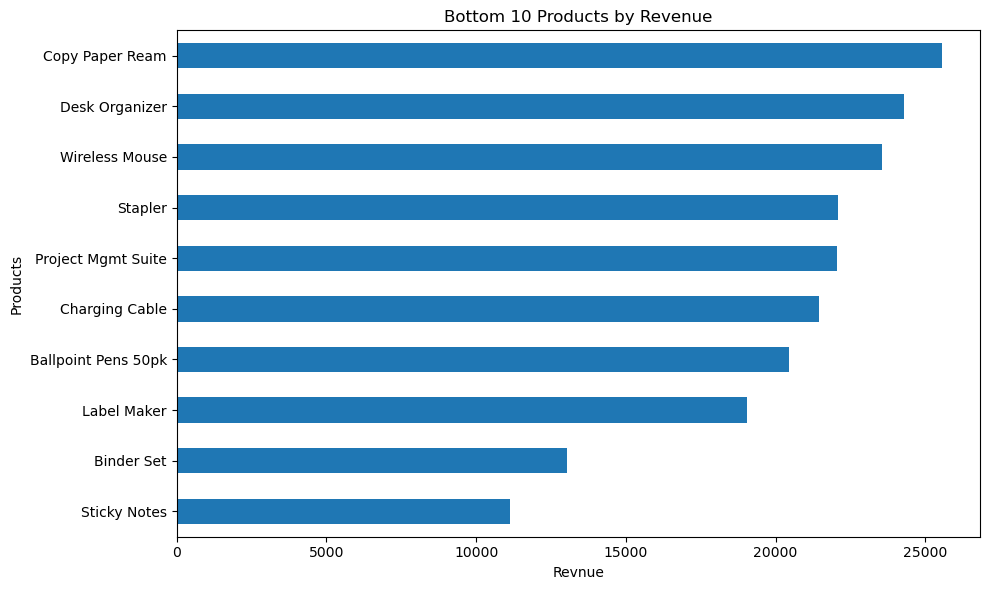

In [37]:
bottom_10_products = product_revenue.tail(10)

bottom_10_products.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Bottom 10 Products by Revenue")
plt.xlabel("Revnue")
plt.ylabel("Products")

plt.tight_layout()
plt.show() # Bottom 10 Products

In [38]:
product_profit = (
    df.groupby("Product")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

product_profit.head(10) # Product by Profit

Product
Analytics Platform       89424.20
Design Studio License    73623.86
Office Suite License     63339.75
Laptop Air 13            44815.69
Cloud Backup 1TB         35369.09
Antivirus Annual         34077.42
Laptop Pro 15            34011.63
Executive Desk           33812.33
Ergonomic Chair          32942.02
4K Monitor 27in          29860.23
Name: Profit, dtype: float64

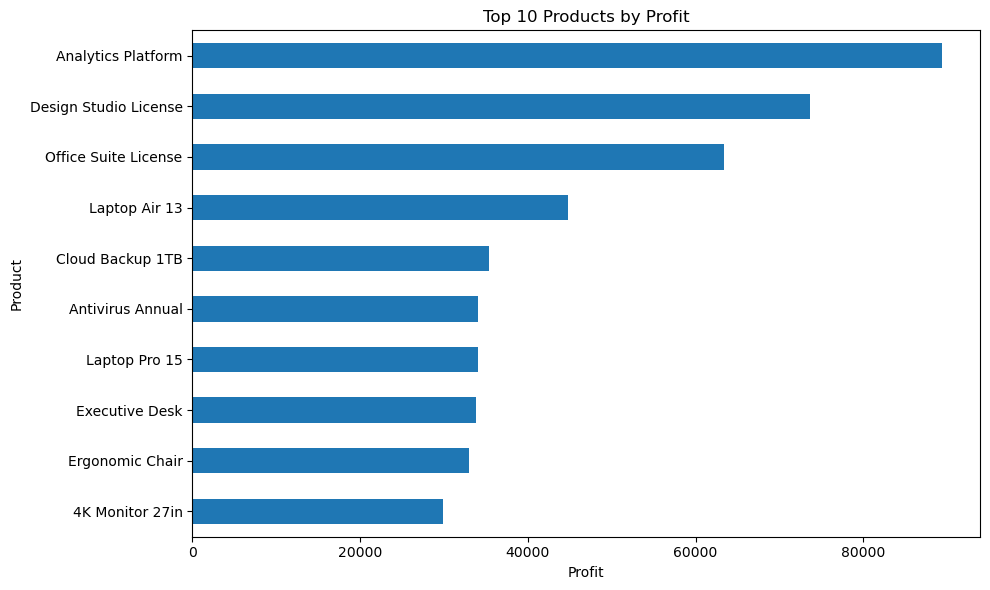

In [39]:
top_profit_products = product_profit.head(10)

plt.figure(figsize=(10, 6))

top_profit_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Profit")
plt.xlabel("Profit")
plt.ylabel("Product")

plt.tight_layout()
plt.show() # Top 10 Products by Profit

In [40]:
loss_products = (
    df.groupby("Product")
    .agg(
        Revenue=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
)

loss_products = loss_products[
    loss_products["Profit"] < 0
].sort_values("Profit")

loss_products # Loss-Making Products

,Revenue,Profit
Product,,
Gaming Laptop X,538332.42,-59695.77
Conference Table,202434.67,-31770.85
Sofa 3-Seater,191292.01,-25126.44
Smartphone Z,363418.37,-24061.62
Water Dispenser,72548.76,-6577.79
Microwave Oven,77117.41,-3428.14


In [41]:
product_performance = df.groupby("Product").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum"),
    Avg_Discount=("Discount", "mean")

)

product_performance["Profit Margin %"] = (
    product_performance["Profit"] /
    product_performance["Revenue"] * 100
)

product_performance = product_performance.sort_values(
    "Revenue",
    ascending=False

)

product_performance.round(2).head(15) # High Revenue But Low Profit

,Revenue,Profit,Quantity,Avg_Discount,Profit Margin %
Product,,,,,
Gaming Laptop X,538332.42,-59695.77,350,0.19,-11.09
Smartphone Z,363418.37,-24061.62,528,0.19,-6.62
Laptop Pro 15,303262.02,34011.63,238,0.11,11.22
Laptop Air 13,302356.62,44815.69,308,0.11,14.82
Conference Table,202434.67,-31770.85,194,0.19,-15.69
Sofa 3-Seater,191292.01,-25126.44,243,0.20,-13.14
Tablet 10in,163904.68,14239.44,361,0.12,8.69
4K Monitor 27in,149927.58,29860.23,357,0.12,19.92
Executive Desk,148048.51,33812.33,233,0.12,22.84


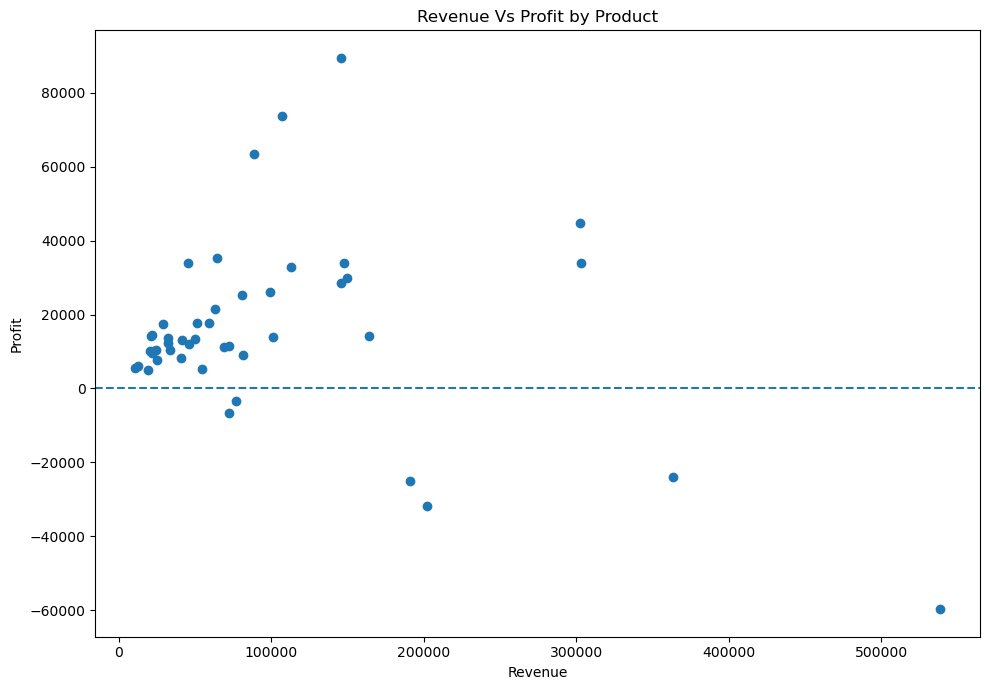

In [43]:
plt.figure(figsize=(10, 7))

plt.scatter(
    product_performance["Revenue"],
    product_performance["Profit"]
)

plt.axhline(0, linestyle="--")
plt.title("Revenue Vs Profit by Product")
plt.xlabel("Revenue")
plt.ylabel("Profit")

plt.tight_layout()
plt.show() # Revenue Vs Profit

In [46]:
top_margin_products = (
    product_performance
    .sort_values("Profit Margin %", ascending=False)
    .head(10)

)

top_margin_products.round(2) # Highest profit Margin Products

,Revenue,Profit,Quantity,Avg_Discount,Profit Margin %
Product,,,,,
Antivirus Annual,45356.03,34077.42,855,0.12,75.13
Office Suite License,88741.65,63339.75,461,0.12,71.38
Design Studio License,107144.00,73623.86,222,0.11,68.71
Charging Cable,21452.92,14182.79,2016,0.11,66.11
Project Mgmt Suite,22059.49,14578.11,715,0.12,66.09
Analytics Platform,145637.51,89424.20,179,0.10,61.40
Phone Case,28914.71,17465.71,1822,0.12,60.40
Cloud Backup 1TB,64579.11,35369.09,608,0.11,54.77
Ballpoint Pens 50pk,20435.17,10003.56,1653,0.11,48.95


In [49]:
product_summary = product_performance.copy()

product_summary["Profitabiity status"] = np.where(
    product_summary["Profit"] < 0,
    "Loss",
    "Profitable"
)

product_summary.round(2).head(20) # Product Performance Summary

,Revenue,Profit,Quantity,Avg_Discount,Profit Margin %,Profitabiity status
Product,,,,,,
Gaming Laptop X,538332.42,-59695.77,350,0.19,-11.09,Loss
Smartphone Z,363418.37,-24061.62,528,0.19,-6.62,Loss
Laptop Pro 15,303262.02,34011.63,238,0.11,11.22,Profitable
Laptop Air 13,302356.62,44815.69,308,0.11,14.82,Profitable
Conference Table,202434.67,-31770.85,194,0.19,-15.69,Loss
Sofa 3-Seater,191292.01,-25126.44,243,0.20,-13.14,Loss
Tablet 10in,163904.68,14239.44,361,0.12,8.69,Profitable
4K Monitor 27in,149927.58,29860.23,357,0.12,19.92,Profitable
Executive Desk,148048.51,33812.33,233,0.12,22.84,Profitable


Customer Analysis

In [50]:
customer_revenue = (
    df.groupby(["Customer ID", "Customer Name"])["Sales"]
    .sum()
    .sort_values(ascending=False)

)

customer_revenue.head(10) # Revenue by Customer

Customer ID  Customer Name  
CUST-0014    Isabella Sharma    105254.36
CUST-0411    Patricia Lewis      99485.64
CUST-0581    Sarah Silva         88067.23
CUST-0298    Matthew Rossi       81115.37
CUST-0387    Mateo Johnson       73107.92
CUST-0541    Mary Martinez       66977.60
CUST-0376    Michael Thomas      64311.93
CUST-0002    Sneha White         53615.96
CUST-0244    Chen Robinson       52573.84
CUST-0522    Thomas Davis        52409.15
Name: Sales, dtype: float64

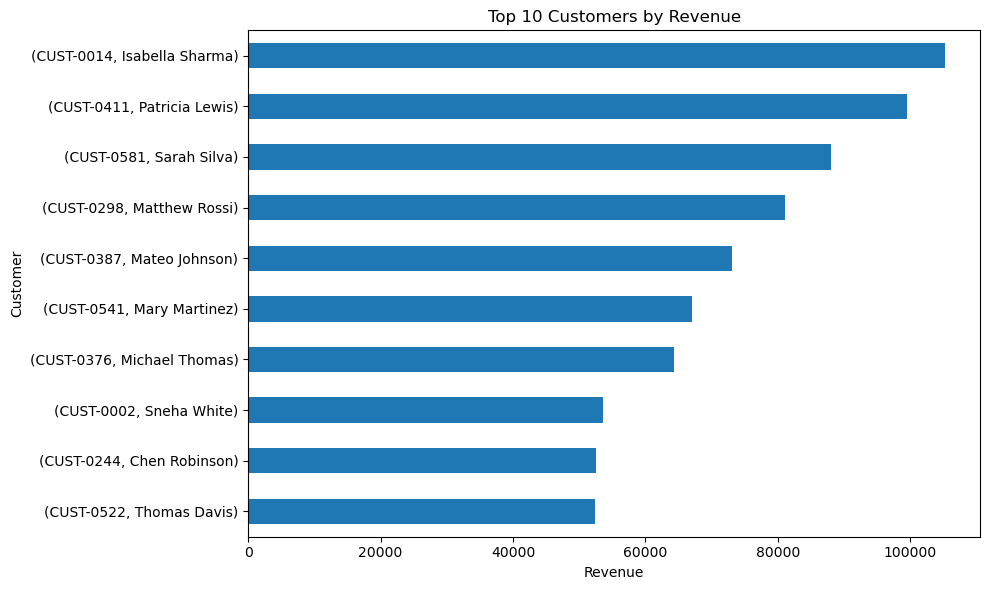

In [51]:
top_10_customers = customer_revenue.head(10)

plt.figure(figsize=(10, 6))

top_10_customers.sort_values().plot(kind="barh")


plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer")

plt.tight_layout()
plt.show() # Top 10 Customers Chart

In [53]:
customer_profit = (
    df.groupby(["Customer ID", "Customer Name"])["Profit"]
    .sum()
    .sort_values(ascending=False)

)

customer_profit.head(10) # Customer Profit

Customer ID  Customer Name  
CUST-0581    Sarah Silva        14477.57
CUST-0411    Patricia Lewis     14092.75
CUST-0387    Mateo Johnson      13935.09
CUST-0014    Isabella Sharma    13368.36
CUST-0541    Mary Martinez      11912.05
CUST-0298    Matthew Rossi      10520.13
CUST-0563    Chen Moore          9972.43
CUST-0002    Sneha White         9290.81
CUST-0244    Chen Robinson       9260.01
CUST-0433    Matthew Nguyen      8622.26
Name: Profit, dtype: float64

In [59]:
customer_performance = df.groupby(
    ["Customer ID", "Customer Name"]
).agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "count"),
    Quantity=("Quantity", "sum")
)

customer_performance["Profit Margin %"] = (
    customer_performance["Profit"] /
    customer_performance["Revenue"] * 100
        )
customer_performance = customer_performance.sort_values(
    "Revenue",
    ascending=False
)

customer_performance.round(2).head(15) # Customer Performance

,,Revenue,Profit,Orders,Quantity,Profit Margin %
Customer ID,Customer Name,,,,,
CUST-0014,Isabella Sharma,105254.36,13368.36,200,572,12.70
CUST-0411,Patricia Lewis,99485.64,14092.75,221,630,14.17
CUST-0581,Sarah Silva,88067.23,14477.57,203,647,16.44
CUST-0298,Matthew Rossi,81115.37,10520.13,188,555,12.97
CUST-0387,Mateo Johnson,73107.92,13935.09,169,535,19.06
CUST-0541,Mary Martinez,66977.60,11912.05,168,496,17.79
CUST-0376,Michael Thomas,64311.93,5927.10,123,382,9.22
CUST-0002,Sneha White,53615.96,9290.81,113,368,17.33
CUST-0244,Chen Robinson,52573.84,9260.01,104,317,17.61


Category Analysis

In [61]:
category_performance = df.groupby("Category").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Quantity=("Quantity", "sum"),
    orders=("Order ID", "count")
)

category_performance["Profit Margin %"] = (
    category_performance["Profit"] /
    category_performance["Revenue"] * 100
)

category_performance.round(2).sort_values(
    "Revenue",
    ascending=False
) # Category Performance

,Revenue,Profit,Quantity,orders,Profit Margin %
Category,,,,,
Electronics,2108773.33,108012.78,3640,2029,5.12
Furniture,954851.06,81713.43,2251,1185,8.56
Software,473517.79,310412.43,3040,1185,65.55
Appliances,402965.81,36588.24,2165,931,9.08
Accessories,293981.27,107033.10,7863,2098,36.41
Office Supplies,232085.68,72533.91,11806,2572,31.25


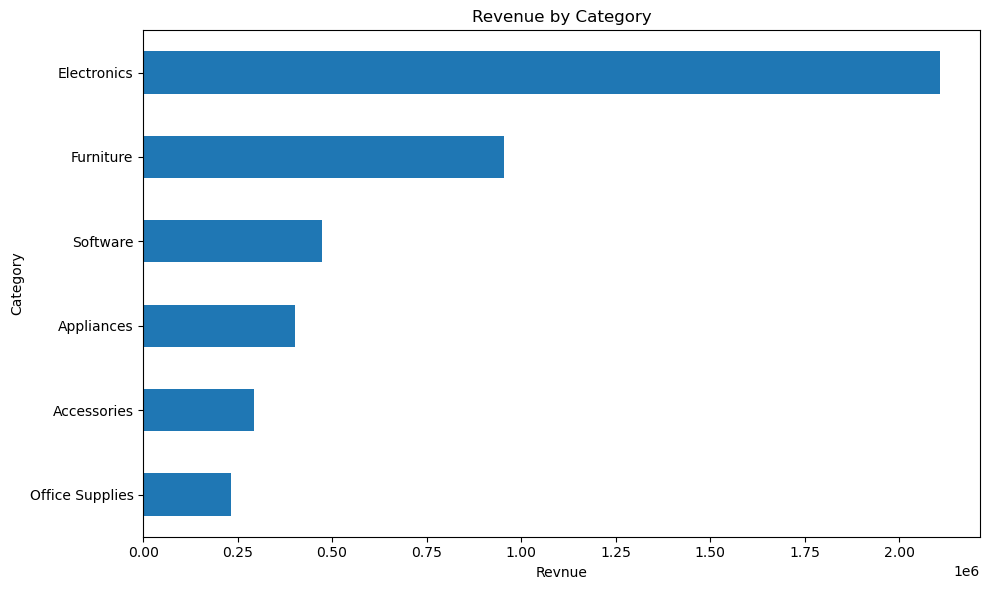

In [65]:
category_performance["Revenue"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Revenue by Category")
plt.xlabel("Revnue")
plt.ylabel("Category")

plt.tight_layout()
plt.show() # Category Revenue Chart

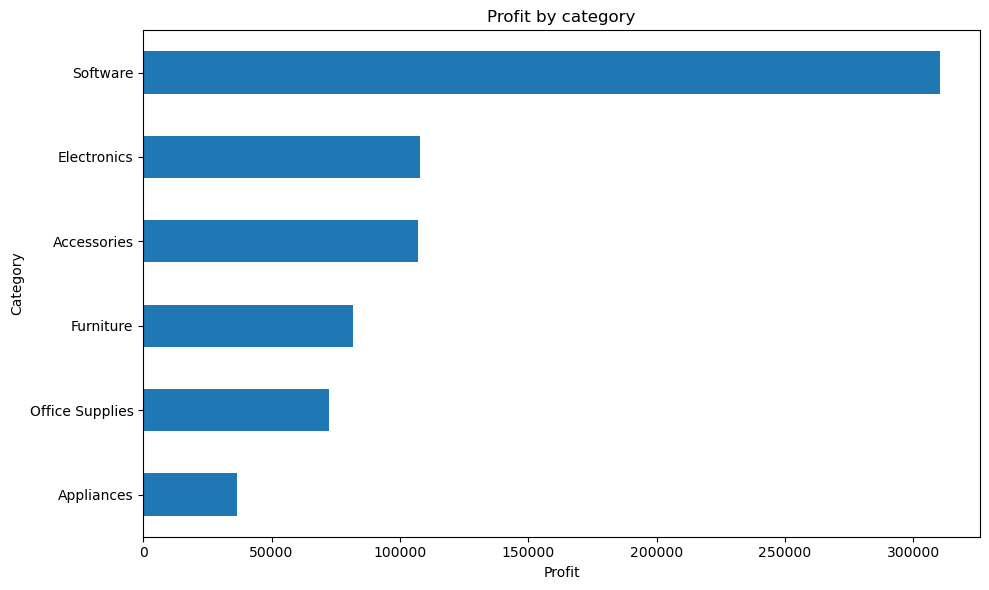

In [67]:
category_performance["Profit"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)

)

plt.title("Profit by category")
plt.xlabel("Profit")
plt.ylabel("Category")

plt.tight_layout()
plt.show() #Category Profit Chart

Discount Analysis

In [72]:
discount_analysis = df.groupby("Discount").agg(
    Revenue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "count")
)

discount_analysis["Profit Margin %"] = (
    discount_analysis["Profit"] /
    discount_analysis["Revenue"] * 100
)

discount_analysis.round(2) # Discount vs Profit

,Revenue,Profit,Orders,Profit Margin %
Discount,,,,
0.00,1093779.41,363662.87,2499,33.25
0.05,625442.51,185200.76,1462,29.61
0.10,724080.10,157302.37,1659,21.72
0.15,545844.97,85374.17,1281,15.64
0.20,563868.00,19332.91,1157,3.43
0.25,425554.29,-15401.51,865,-3.62
0.30,269597.45,-33202.44,557,-12.32
0.35,145673.34,-24160.12,357,-16.59
0.40,72334.87,-21815.12,163,-30.16


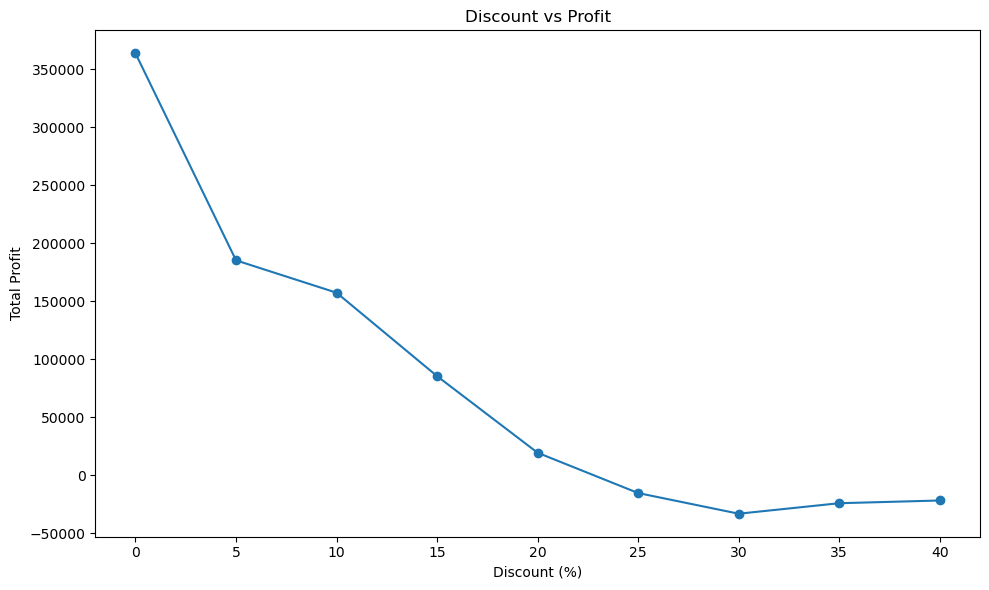

In [76]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_analysis.index * 100,
    discount_analysis["Profit"],
    marker="o"
)

plt.title("Discount vs Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Total Profit")

plt.tight_layout()
plt.show() # Discount Vs Profit Chart

In [80]:
high_discount_products = (
    product_performance
    .sort_values("Avg_Discount", ascending=False)
    .head(10)
)

high_discount_products.round(2) # High Discount Products

,Revenue,Profit,Quantity,Avg_Discount,Profit Margin %
Product,,,,,
Sofa 3-Seater,191292.01,-25126.44,243,0.20,-13.14
Microwave Oven,77117.41,-3428.14,687,0.20,-4.45
Gaming Laptop X,538332.42,-59695.77,350,0.19,-11.09
Smartphone Z,363418.37,-24061.62,528,0.19,-6.62
Conference Table,202434.67,-31770.85,194,0.19,-15.69
Water Dispenser,72548.76,-6577.79,288,0.18,-9.07
Visitor Chair,63079.76,21550.66,553,0.13,34.16
Filing Cabinet,41118.02,8367.52,223,0.13,20.35
Smart Speaker,46152.95,11914.98,479,0.12,25.82


In [81]:
loss_product_analysis = df.groupby("Product").agg(
    Revnue=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean"),
    Quantity=("Quantity", "sum")
)

loss_product_analysis = loss_product_analysis[
    loss_product_analysis["Profit"] < 0
    ].sort_values("Profit")

loss_product_analysis.round(2) # Loss-Making Products = Discount

,Revnue,Profit,Avg_Discount,Quantity
Product,,,,
Gaming Laptop X,538332.42,-59695.77,0.19,350
Conference Table,202434.67,-31770.85,0.19,194
Sofa 3-Seater,191292.01,-25126.44,0.20,243
Smartphone Z,363418.37,-24061.62,0.19,528
Water Dispenser,72548.76,-6577.79,0.18,288
Microwave Oven,77117.41,-3428.14,0.20,687


In [85]:
monthly_profit = (
    df.groupby("Month")["Profit"]
    .sum()
)

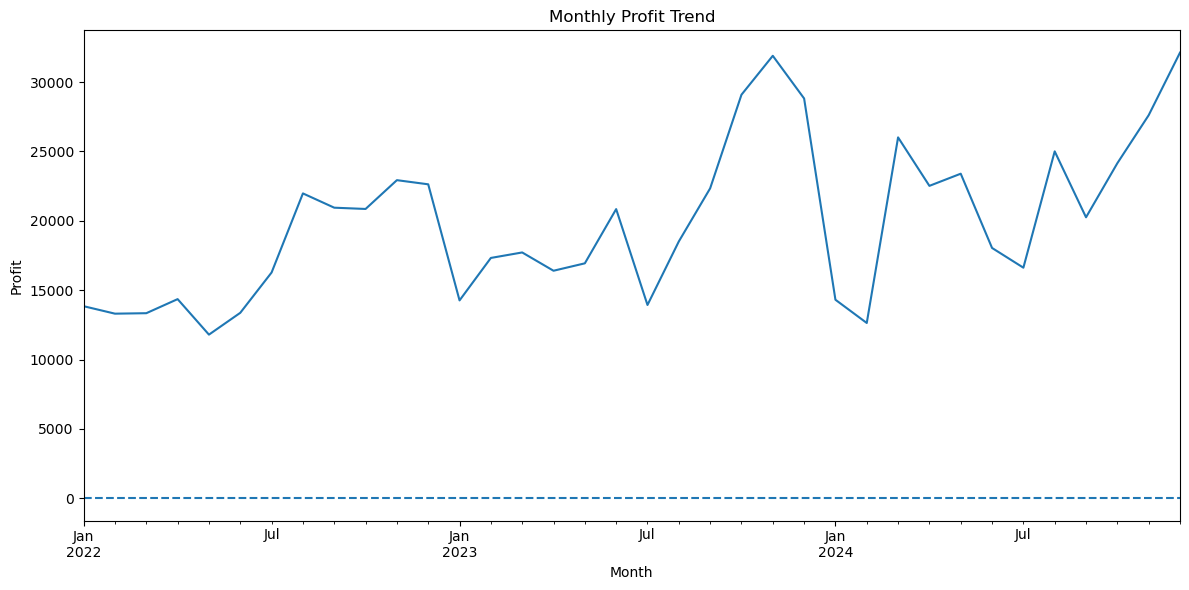

In [87]:
plt.figure(figsize=(12, 6))

monthly_profit.plot()

plt.axhline(0, linestyle="--")

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")

plt.tight_layout()
plt.show() # Monthly Profit Analysis

In [89]:
yearly_profit = (
    df.groupby(df["Order Date"].dt.year)["Profit"]
    .sum()

)

yearly_profit # Yearly Profit

Order Date
2022    205594.40
2023    248043.38
2024    262656.11
Name: Profit, dtype: float64

In [90]:
yearly_profit_growth = yearly_profit.pct_change() * 100

yearly_profit_growth.round(2)

Order Date
2022      NaN
2023    20.65
2024     5.89
Name: Profit, dtype: float64

SQL Analysis

In [94]:
import sqlite3

# Create a copy for SQL
sql_df = df.copy()

# Convert Period columns to text because SQLite does not support Period type
sql_df["Month"] = sql_df["Month"].astype(str)
sql_df["Quarter"] = sql_df["Quarter"].astype(str)

# Create SQLite database
conn = sqlite3.connect("sales_analysis.db")

# Write dataframe to SQL table
sql_df.to_sql(
    "sales",
    conn,
    if_exists="replace",
    index=False
)

print("Sales table created successfully!")
print("Rows inserted:", len(sql_df))

Sales table created successfully!
Rows inserted: 10000


In [95]:
sql_df

,Order ID,Order Date,Customer ID,Customer Name,Product,Category,Region,Sales,Quantity,Discount,Cost,Profit,Month,Quarter
0,ORD-100001,2022-01-01,CUST-0356,Joseph Brown,Charging Cable,Accessories,South,80.66,7,0.00,26.70,53.96,2022-01,2022Q1
1,ORD-100002,2022-01-01,CUST-0127,John Patel,Sticky Notes,Office Supplies,West,16.71,3,0.05,7.97,8.74,2022-01,2022Q1
2,ORD-100003,2022-01-01,CUST-0411,Patricia Lewis,Mechanical Keyboard,Accessories,East,262.76,3,0.00,143.88,118.88,2022-01,2022Q1
3,ORD-100004,2022-01-02,CUST-0387,Mateo Johnson,Executive Desk,Furniture,Central,1467.05,2,0.05,971.34,495.71,2022-01,2022Q1
4,ORD-100005,2022-01-02,CUST-0432,Thomas Taylor,Laptop Bag,Accessories,East,67.81,1,0.00,33.83,33.98,2022-01,2022Q1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,ORD-109996,2024-12-31,CUST-0356,Joseph Brown,4K Monitor 27in,Electronics,East,815.12,2,0.15,674.04,141.08,2024-12,2024Q4
9996,ORD-109997,2024-12-31,CUST-0422,Richard Rossi,Cloud Backup 1TB,Software,North,469.83,4,0.00,190.37,279.46,2024-12,2024Q4
9997,ORD-109998,2024-12-31,CUST-0409,Li Taylor,Sticky Notes,Office Supplies,South,29.75,5,0.00,13.39,16.36,2024-12,2024Q4
9998,ORD-109999,2024-12-31,CUST-0278,Mateo Wilson,USB-C Hub,Accessories,East,43.85,1,0.00,23.12,20.73,2024-12,2024Q4


In [98]:
query = """
SELECT
    Product,
    SUM(Sales) AS Revenue,
    SUM(Profit) AS Profit
FROM sales
GROUP BY Product
ORDER BY Revenue DESC
LIMIT 10;
"""

sql_top_products = pd.read_sql_query(query, conn)

sql_top_products # SQL Top Products

,Product,Revenue,Profit
0,Gaming Laptop X,538332.42,-59695.77
1,Smartphone Z,363418.37,-24061.62
2,Laptop Pro 15,303262.02,34011.63
3,Laptop Air 13,302356.62,44815.69
4,Conference Table,202434.67,-31770.85
5,Sofa 3-Seater,191292.01,-25126.44
6,Tablet 10in,163904.68,14239.44
7,4K Monitor 27in,149927.58,29860.23
8,Executive Desk,148048.51,33812.33
9,Standing Desk,145895.03,28428.91


In [101]:
query = """
SELECT 
     Product,
     SUM(Sales) AS Revenue,
     SUM(Profit) AS Profit
FROM sales
GROUP BY Product
HAVING SUM(Profit) < 0
ORDER BY Profit ASC;
"""

sql_loss_products = pd.read_sql_query(query, conn)

sql_loss_products # SQL Loss-Making Products

,Product,Revenue,Profit
0,Gaming Laptop X,538332.42,-59695.77
1,Conference Table,202434.67,-31770.85
2,Sofa 3-Seater,191292.01,-25126.44
3,Smartphone Z,363418.37,-24061.62
4,Water Dispenser,72548.76,-6577.79
5,Microwave Oven,77117.41,-3428.14


In [103]:
query = """
SELECT 
      Region,
      SUM(Sales) AS Revenue,
      SUM(profit) AS Profit,
      ROUND(SUM(Profit) * 100.0 / SUM(Sales), 2) AS Profit_Margin
FROM sales
GROUP BY Region
ORDER BY Revenue DESC;
"""

sql_region = pd.read_sql_query(query, conn)

sql_region # SQL Top Customers

,Region,Revenue,Profit,Profit_Margin
0,East,1376225.04,226548.21,16.46
1,North,1024203.41,166299.63,16.24
2,West,860382.96,136038.16,15.81
3,South,638679.54,93172.80,14.59
4,Central,566683.99,94235.09,16.63


POWER BI 


In [104]:
df.to_csv(
    "sales_analysis_clean.csv",
    index=False
)

print("power BI dataset exported successfully!")

power BI dataset exported successfully!
